Distributia a priori:     Beta(2, 18)
Distributia a posteriori: Beta(10, 60)

Estimatorul MLE:         0.1600 (16.00%)
Estimatorul MAP:         0.1324 (13.24%)
Media a posteriori:      0.1429 (14.29%)

Interval credibil 95%:   [0.0717, 0.2332]

P(theta < 10% | Date) =  0.1484 (14.84%)

Predictie 10 piese bune: 0.2360 (23.60%)



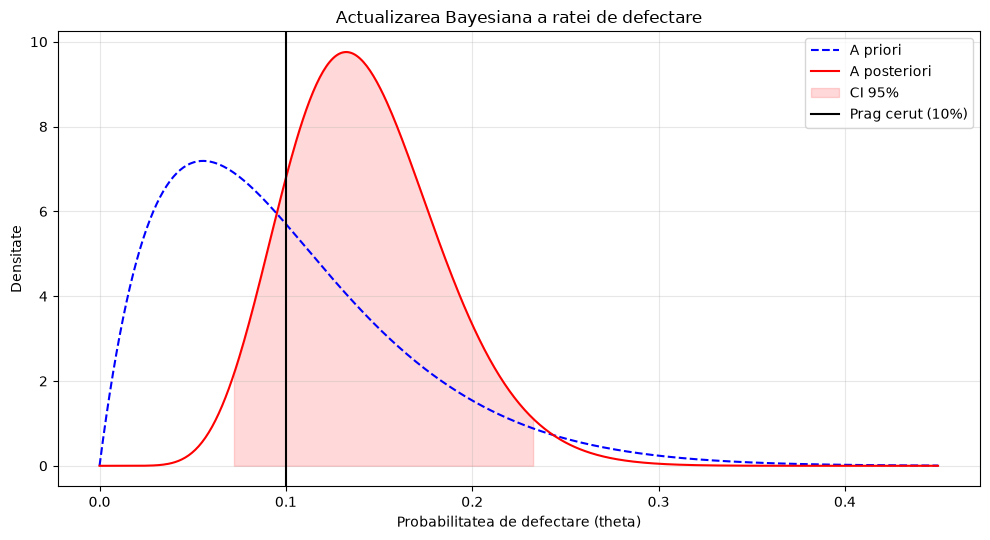

Valoarea max. a lui 'a' (pt. 95% sanse per client): 0.13 minute

Timpul mediu total in sistem (cu a = 0.13):   5.11 minute

Simularea a folosit M = 20.000 (pentru cautare), M = 50.000 (pentru media finala).


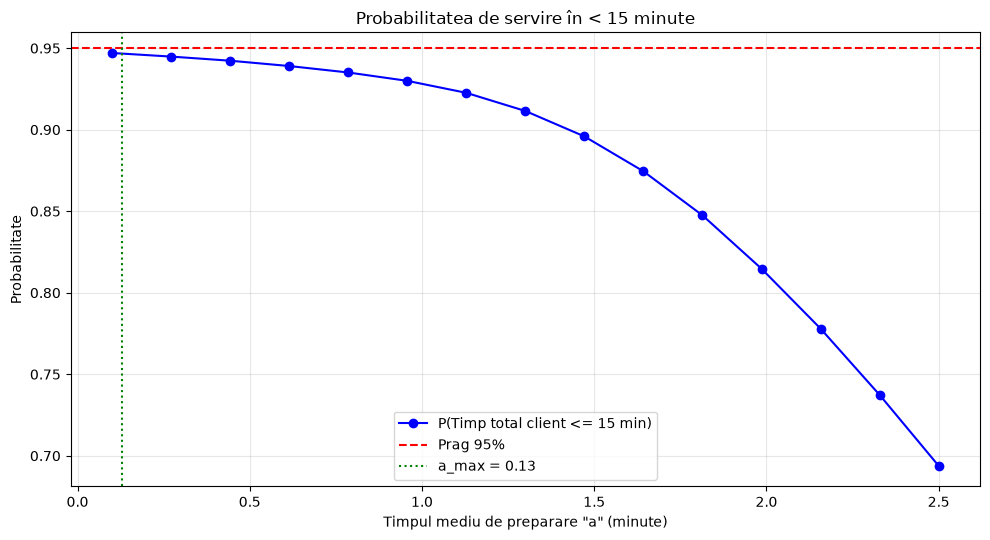

In [3]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


# 1

# a)
# Modelul este Y|theta ~ Binomial(n, theta) 
# distributia a priori este Beta(alpha_prior, beta_prior).
alpha_prior, beta_prior = 2, 18
n, y = 50, 8

# b)
# Calculăm parametrii distributiei a posteriori folosind conjugarea Beta-Binomial
alpha_post = alpha_prior + y
beta_post = beta_prior + (n - y)
print(f"Distributia a priori:     Beta({alpha_prior}, {beta_prior})")
print(f"Distributia a posteriori: Beta({alpha_post}, {beta_post})\n")

# c)
# MLE = y / n
theta_mle = y / n
# MAP = (alpha - 1) / (alpha + beta - 2)
theta_map = (alpha_post - 1) / (alpha_post + beta_post - 2)
# Media a posteriori = alpha / (alpha + beta)
theta_mean = alpha_post / (alpha_post + beta_post)

print(f"Estimatorul MLE:         {theta_mle:.4f} ({theta_mle*100:.2f}%)")
print(f"Estimatorul MAP:         {theta_map:.4f} ({theta_map*100:.2f}%)")
print(f"Media a posteriori:      {theta_mean:.4f} ({theta_mean*100:.2f}%)\n")

# e)
ci_low, ci_high = stats.beta.ppf([0.025, 0.975], alpha_post, beta_post)
print(f"Interval credibil 95%:   [{ci_low:.4f}, {ci_high:.4f}]\n")

# f)
prob_sub_10 = stats.beta.cdf(0.10, alpha_post, beta_post)
print(f"P(theta < 10% | Date) =  {prob_sub_10:.4f} ({prob_sub_10*100:.2f}%)\n")

# g)
prob_pred_0 = stats.betabinom.pmf(0, 10, alpha_post, beta_post)
print(f"Predictie 10 piese bune: {prob_pred_0:.4f} ({prob_pred_0*100:.2f}%)\n")

# d)

theta_grid = np.linspace(0, 0.45, 500)
plt.plot(theta_grid, stats.beta.pdf(theta_grid, alpha_prior, beta_prior), 'b--', label='A priori')
plt.plot(theta_grid, stats.beta.pdf(theta_grid, alpha_post, beta_post), 'r-', label='A posteriori')
plt.fill_between(theta_grid, stats.beta.pdf(theta_grid, alpha_post, beta_post), 
                 where=(theta_grid >= ci_low) & (theta_grid <= ci_high), 
                 color='red', alpha=0.15, label='CI 95%')
plt.axvline(0.10, color='black', label='Prag cerut (10%)')
plt.title('Actualizarea Bayesiana a ratei de defectare')
plt.xlabel('Probabilitatea de defectare (theta)')
plt.ylabel('Densitate')
plt.legend()
plt.tight_layout()
plt.show()

# 2

# a)
def evalueaza_performanta(a, n_sim=20000, seed=42):
    rng = np.random.default_rng(seed)
    ore_succes = 0
    toti_timpii = []
    
    for _ in range(n_sim):
        n_clienti = rng.poisson(20.0)
        if n_clienti == 0:
            ore_succes += 1
            continue
            
        sosiri = np.sort(rng.uniform(0.0, 60.0, size=n_clienti))
        timpi_plata = rng.exponential(scale=2.0, size=n_clienti)
        timpi_gatit = rng.exponential(scale=a, size=n_clienti) if a > 0 else np.zeros(n_clienti)
        
        term_plata, term_gatit = np.empty(n_clienti), np.empty(n_clienti)
        tp_prev, tg_prev = 0.0, 0.0
        
        for i in range(n_clienti):
            tp_prev = max(sosiri[i], tp_prev) + timpi_plata[i]
            term_plata[i] = tp_prev
            
            tg_prev = max(tp_prev, tg_prev) + timpi_gatit[i]
            term_gatit[i] = tg_prev
            
        timp_sistem = term_gatit - sosiri
        toti_timpii.append(timp_sistem)
        
        if np.max(timp_sistem) <= 15.0:
            ore_succes += 1
            
    toti_timpii = np.concatenate(toti_timpii)
    prob_ora = ore_succes / n_sim
    prob_client = np.mean(toti_timpii <= 15.0)
    
    return prob_ora, prob_client, np.mean(toti_timpii)

# b)
low, high = 0.05, 2.50
for _ in range(12):
    mid = (low + high) / 2
    _, p_client, _ = evalueaza_performanta(mid, n_sim=20000)
    if p_client >= 0.95:
        low = mid
    else:
        high = mid
a_optim = low

print(f"Valoarea max. a lui 'a' (pt. 95% sanse per client): {a_optim:.2f} minute\n")

# c)
_, _, t_mediu = evalueaza_performanta(a_optim, n_sim=50000)
print(f"Timpul mediu total in sistem (cu a = {a_optim:.2f}):   {t_mediu:.2f} minute\n")

# d)
print(f"Simularea a folosit M = 20.000 (pentru cautare), M = 50.000 (pentru media finala).")

a_vals = np.linspace(0.1, 2.5, 15)
prob_list = [evalueaza_performanta(val, n_sim=5000)[1] for val in a_vals]

plt.figure()
plt.plot(a_vals, prob_list, 'b-o', label='P(Timp total client <= 15 min)')
plt.axhline(0.95, color='r', linestyle='--', label='Prag 95%')
plt.axvline(a_optim, color='g', linestyle=':', label=f'a_max = {a_optim:.2f}')
plt.title('Probabilitatea de servire în < 15 minute')
plt.xlabel('Timpul mediu de preparare "a" (minute)')
plt.ylabel('Probabilitate')
plt.legend()
plt.tight_layout()
plt.show()

## Ex. 1

**a)**
Testele pieselor sunt independente. Variabila $Y$ urmeaza distributia Binomiala:
$$Y \mid \theta \sim \text{Binomial}(50, \theta)$$
Functia de verosimilitate este:
$$L(\theta) = \binom{50}{8} \theta^8 (1 - \theta)^{42}$$

**b)**
Din distributia a priori $\text{Beta}(2, 18)$ si cele 8 piese defecte din 50 obtinem o noua distributie, cu parametrii $10$ si $60$. Astfel, distributia a posteriori este **$\text{Beta}(10, 60)$**.

**c)**
* **Estimatorul MLE:** $0.1600$ (16%)
* **Estimatorul MAP:** $0.1324$ (13.24%)
* **Media a posteriori:** $0.1429$ (14.29%)
*Comparatie:* Observarea a 8 defecte trage media a priori (10%) inspre estimarea MLE (16%), ajungand la $\approx$ 14.3%.

**d)**
Cresterea volumului de date a redus dispersia (incertitudinea) si a mutat distributia a posteriori spre dreapta, fata de cea a priori.

**f)**
Probabilitatea a posteriori $P(\theta < 0.10 \mid Y = 8)$ este **$0.1484$ ($14.84\%$)**. Datele nu sustin cerinta fabricii ca rata sa fie sub 10%.

**g)**
Probabilitatea de a obtine 10 piese noi bune, marginalizand peste $\theta$, este de **$0.2360$ ($23.60\%$)**.


## Ex. 2

**a)**
Sistemul utilizeaza doua cozi FIFO in serie.
1. Clientul incepe plata daca a sosit si daca casa e libera.
2. Prepararea incepe doar dupa terminarea platii si dupa ce bucataria e libera. Timpul total este diferenta dintre finalizarea gatitului si sosire.

**b)**
Prin metoda bisectiei, s-a estimat ca timpul mediu de preparare trebuie sa fie **$a \approx 0.13$ minute** pentru ca 95% dintre clienti sa primească comanda in $\le 15$ minute.


**d)**
S-au utilizat **$20.000$** simulari pentru cautare si **$50.000$** pentru evaluarea finala. Fluctuatiile apar deoarece simularile utilizeaza secvente pseudo-aleatoare diferite, insa utilizarea aceluiasi `seed` asigura reproductibilitatea valorilor.